# Saudi Podcast EDA

This notebook looks at Saudi podcast videos collected from YouTube. I focus on views, engagement, video length, channels, and publication timing. The collection script is kept separate in `collect_youtube_data.py`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [2]:
pd.set_option("display.max_rows", 5)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

In [3]:
df = pd.read_csv("../data/clean_data.csv")

print("Shape:", df.shape)
df.head()

Shape: (648, 15)


,video_id,video_title,channel_name,channel_id,published_at,matched_search,views,likes,comments,duration,video_url,collected_at,duration_readable,duration_seconds,duration_minutes
0,pJ0auP7dbcY,كيف تنجح العلاقات مع ياسر الحزيمي | بودكاست فنجان,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2022-11-16T13:00:26Z,"""ثمانية"" حلقة",165305543,2154646.0,64397.0,PT3H3M9S,https://www.youtube.com/watch?v=pJ0auP7dbcY,2026-10-28T05:24:07.014016+00:00,3:03:09,10989.0,183.150000
1,oP4e7a2keKc,العزلة والشهرة والحزن مع عائض القرني | بودكاست...,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-03-15T15:00:42Z,"""ثمانية"" حلقة",43118967,180078.0,9497.0,PT3H12M42S,https://www.youtube.com/watch?v=oP4e7a2keKc,2026-10-28T05:24:04.768381+00:00,3:12:42,11562.0,192.700000
2,Sl24jUcidN8,لماذا خسر المسلمون الحضارة العربية | بودكاست ف...,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-03-08T15:00:30Z,"""فنجان"" حلقة",15673317,109036.0,9765.0,PT2H7M,https://www.youtube.com/watch?v=Sl24jUcidN8,2026-10-28T05:24:07.205436+00:00,2:07:00,7620.0,127.000000
3,D1gL-vlmyQ8,عسير: التاريخ غير المكتوب | بودكاست فنجان,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-01-18T15:00:08Z,"""ثمانية"" حلقة",13205087,40069.0,5785.0,PT3H43M37S,https://www.youtube.com/watch?v=D1gL-vlmyQ8,2026-10-28T05:24:07.014559+00:00,3:43:37,13417.0,223.616667
4,9gEPoVlHX6w,التاريخ المجهول لليهود وإسرائيل | بودكاست فنجان,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-05-24T15:00:06Z,"""ثمانية"" حلقة",13097987,82938.0,6321.0,PT2H45M15S,https://www.youtube.com/watch?v=9gEPoVlHX6w,2026-10-28T05:24:07.014142+00:00,2:45:15,9915.0,165.250000


In [4]:
df.tail()

,video_id,video_title,channel_name,channel_id,published_at,matched_search,views,likes,comments,duration,video_url,collected_at,duration_readable,duration_seconds,duration_minutes
643,2339P6t6UeM,ماذا نعني بتصميم نمط الحياة؟ | بودكاست #ذا_قال,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2026-06-04T19:00:23Z,"""ذا قال"" حلقة",6547,37.0,7.0,PT2M21S,https://www.youtube.com/watch?v=2339P6t6UeM,2026-10-28T05:24:04.768651+00:00,2:21,NaN,2.350000
644,Gm3854poYJU,ليش ارتبطت الفئران بالأوبئة | بودكاست #سقراط,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2026-06-23T22:00:37Z,"""سقراط"" حلقة",5515,87.0,2.0,PT2M4S,https://www.youtube.com/watch?v=Gm3854poYJU,2026-10-28T05:24:07.790703+00:00,2:04,NaN,2.066667
645,ub013sZNJvQ,حلقة زخم اليوم مع رامي بوسبيت ! #بودكاست #زخم,فراغ,UCuw5c-KJXcjUijddr292_dg,2026-03-07T17:53:47Z,"""فراغ"" حلقة",1280,16.0,0.0,PT34S,https://www.youtube.com/watch?v=ub013sZNJvQ,2026-10-28T05:24:06.462634+00:00,0:34,NaN,0.566667
646,Usil_d4QYOQ,حلقة زخم اليوم مع علي آل محسن! #بودكاست #زخم,فراغ,UCuw5c-KJXcjUijddr292_dg,2026-05-09T16:59:05Z,"""فراغ"" حلقة",399,2.0,0.0,PT59S,https://www.youtube.com/watch?v=Usil_d4QYOQ,2026-10-28T05:24:06.462609+00:00,0:59,NaN,0.983333
647,FvlCZCVDZ7M,حلقة زخم اليوم مع تركي الشهري! #بودكاست #زخم,فراغ,UCuw5c-KJXcjUijddr292_dg,2026-04-24T14:30:20Z,"""فراغ"" حلقة",318,1.0,0.0,PT35S,https://www.youtube.com/watch?v=FvlCZCVDZ7M,2026-10-28T05:24:06.462574+00:00,0:35,NaN,0.583333


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 648 entries, 0 to 647
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   video_id           648 non-null    object 
 1   video_title        648 non-null    object 
 2   channel_name       648 non-null    object 
 3   channel_id         648 non-null    object 
 4   published_at       648 non-null    object 
 5   matched_search     648 non-null    object 
 6   views              648 non-null    int64  
 7   likes              648 non-null    float64
 8   comments           648 non-null    float64
 9   duration           648 non-null    object 
 10  video_url          648 non-null    object 
 11  collected_at       648 non-null    object 
 12  duration_readable  648 non-null    object 
 13  duration_seconds   599 non-null    float64
 14  duration_minutes   648 non-null    float64
dtypes: float64(4), int64(1), object(10)
memory usage: 76.1+ KB


In [6]:
print("Missing values before cleaning:")
display(df.isna().sum())

Missing values before cleaning:


video_id             0
video_title          0
                    ..
duration_seconds    49
duration_minutes     0
Length: 15, dtype: int64

In [7]:
!apt-get -qq install fonts-noto-core
!pip -q install arabic-reshaper python-bidi

'apt-get' is not recognized as an internal or external command,
operable program or batch file.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\Huawei\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [8]:
import glob
import matplotlib.font_manager as fm
from matplotlib.ticker import FuncFormatter
import arabic_reshaper
from bidi.algorithm import get_display

# Fonts installed with apt are not visible to matplotlib until they are registered
for path in glob.glob("/usr/share/fonts/**/Noto*Arabic*.[to]tf", recursive=True):
    fm.fontManager.addfont(path)

_available = {f.name for f in fm.fontManager.ttflist}
ARABIC_FONTS = [
    f for f in ("Noto Naskh Arabic", "Noto Sans Arabic") if f in _available
] + ["DejaVu Sans"]


def use_arabic_font():
    """Call again after sns.set_theme(), which resets the font."""
    plt.rcParams["font.family"] = ARABIC_FONTS
    plt.rcParams["axes.unicode_minus"] = False


use_arabic_font()
print("Fonts used:", ARABIC_FONTS)


def ar(text):
    """Reshape + reorder Arabic so it is drawn correctly (not reversed)."""
    if not isinstance(text, str):
        return str(text)
    return get_display(arabic_reshaper.reshape(text))


def short_ar(text, n=45):
    """Truncate long titles BEFORE reshaping, then fix the Arabic."""
    text = str(text)
    if len(text) > n:
        text = text[: n - 1].rstrip() + "…"
    return ar(text)


def barh_labeled(ax, labels, values, **kwargs):
    """Horizontal bars by position, so duplicate labels never merge."""
    pos = list(range(len(labels)))
    ax.barh(pos, values, **kwargs)
    ax.set_yticks(pos)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()


# Thousands separators for axes (also readable on log scales)
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")

Fonts used: ['DejaVu Sans']


In [9]:
print(df.isnull().sum())

video_id             0
video_title          0
                    ..
duration_seconds    49
duration_minutes     0
Length: 15, dtype: int64


In [10]:
df['comments'] = df['comments'].fillna(0)

print(df.isnull().sum())

video_id             0
video_title          0
                    ..
duration_seconds    49
duration_minutes     0
Length: 15, dtype: int64


In [11]:
df.duplicated().sum()

0

In [12]:
import re

def duration_to_seconds(value):
    if pd.isna(value):
        return None

    s = str(value).strip()
    pattern = (
        r"PT"
        r"(?:(\d+)H)?"
        r"(?:(\d+)M)?"
        r"(?:(\d+(?:\.\d+)?)S)?"
    )
    match = re.fullmatch(pattern, s)

    if not match:
        return None

    h, m, sec = match.groups()

    return (
        int(h or 0) * 3600
        + int(m or 0) * 60
        + float(sec or 0)
    )

df["duration_minutes"] = (
    df["duration"].apply(duration_to_seconds) / 60
)

print(df[["duration", "duration_minutes"]].head())
print("المدد غير المقروءة:", df["duration_minutes"].isna().sum())

df.to_csv("clean_data.csv", index=False, encoding="utf-8-sig")

     duration  duration_minutes
0    PT3H3M9S        183.150000
1  PT3H12M42S        192.700000
2      PT2H7M        127.000000
3  PT3H43M37S        223.616667
4  PT2H45M15S        165.250000
المدد غير المقروءة: 0


In [13]:
df.columns

Index(['video_id', 'video_title', 'channel_name', 'channel_id', 'published_at', 'matched_search', 'views', 'likes',
       'comments', 'duration', 'video_url', 'collected_at', 'duration_readable', 'duration_seconds',
       'duration_minutes'],
      dtype='object')

In [14]:
df["duration_minutes"] = pd.to_numeric(
    df["duration_minutes"], errors="coerce"
)

In [15]:
df["published_at"] = pd.to_datetime(
    df["published_at"], errors="coerce", utc=True
)

df["published_at"] = df["published_at"].dt.tz_convert(
    "Asia/Riyadh"
)

df["publish_date"] = df["published_at"].dt.date
df["publish_hour"] = df["published_at"].dt.hour
df["publish_day"] = df["published_at"].dt.day_name()

In [16]:
for col in ["views", "likes", "comments", "duration_minutes"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [17]:
df_backup = df.copy()

print("عدد المقاطع قبل الفلترة:", len(df))
print("عدد المدد المفقودة:", df["duration_minutes"].isna().sum())
print(df["duration_minutes"].describe())

عدد المقاطع قبل الفلترة: 648
عدد المدد المفقودة: 0
count    648.000000
mean      99.611034
            ...    
75%      123.745833
max      304.233333
Name: duration_minutes, Length: 8, dtype: float64


In [18]:
df_filtered = df[
    df["duration_minutes"].notna()
    & (df["duration_minutes"] >= 30)
].copy()

print("عدد المقاطع بعد الفلترة:", len(df_filtered))

df = df_filtered.copy()

عدد المقاطع بعد الفلترة: 599


In [19]:
print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
display(df.isna().sum())
df.head()


Shape after cleaning: (599, 18)
Missing values after cleaning:


video_id        0
video_title     0
               ..
publish_hour    0
publish_day     0
Length: 18, dtype: int64

,video_id,video_title,channel_name,channel_id,published_at,matched_search,views,likes,comments,duration,video_url,collected_at,duration_readable,duration_seconds,duration_minutes,publish_date,publish_hour,publish_day
0,pJ0auP7dbcY,كيف تنجح العلاقات مع ياسر الحزيمي | بودكاست فنجان,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2022-11-16 16:00:26+03:00,"""ثمانية"" حلقة",165305543,2154646.0,64397.0,PT3H3M9S,https://www.youtube.com/watch?v=pJ0auP7dbcY,2026-10-28T05:24:07.014016+00:00,3:03:09,10989.0,183.150000,2022-11-16,16,Wednesday
1,oP4e7a2keKc,العزلة والشهرة والحزن مع عائض القرني | بودكاست...,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-03-15 18:00:42+03:00,"""ثمانية"" حلقة",43118967,180078.0,9497.0,PT3H12M42S,https://www.youtube.com/watch?v=oP4e7a2keKc,2026-10-28T05:24:04.768381+00:00,3:12:42,11562.0,192.700000,2023-03-15,18,Wednesday
2,Sl24jUcidN8,لماذا خسر المسلمون الحضارة العربية | بودكاست ف...,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-03-08 18:00:30+03:00,"""فنجان"" حلقة",15673317,109036.0,9765.0,PT2H7M,https://www.youtube.com/watch?v=Sl24jUcidN8,2026-10-28T05:24:07.205436+00:00,2:07:00,7620.0,127.000000,2023-03-08,18,Wednesday
3,D1gL-vlmyQ8,عسير: التاريخ غير المكتوب | بودكاست فنجان,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-01-18 18:00:08+03:00,"""ثمانية"" حلقة",13205087,40069.0,5785.0,PT3H43M37S,https://www.youtube.com/watch?v=D1gL-vlmyQ8,2026-10-28T05:24:07.014559+00:00,3:43:37,13417.0,223.616667,2023-01-18,18,Wednesday
4,9gEPoVlHX6w,التاريخ المجهول لليهود وإسرائيل | بودكاست فنجان,إذاعة ثمانية,UCwjLh640nGXSGa9iHRS31ag,2023-05-24 18:00:06+03:00,"""ثمانية"" حلقة",13097987,82938.0,6321.0,PT2H45M15S,https://www.youtube.com/watch?v=9gEPoVlHX6w,2026-10-28T05:24:07.014142+00:00,2:45:15,9915.0,165.250000,2023-05-24,18,Wednesday


In [20]:
df.tail()

,video_id,video_title,channel_name,channel_id,published_at,matched_search,views,likes,comments,duration,video_url,collected_at,duration_readable,duration_seconds,duration_minutes,publish_date,publish_hour,publish_day
634,_29SUEs5dQs,فينكس: تحديات الإدارة وصناعة أبطال الفنون القت...,إذاعة مختلف,UC8vdjzu_0QMQlG9qNT5D_AQ,2026-10-24 18:39:16+03:00,"""بترولي"" حلقة",13211,163.0,17.0,PT1H26M41S,https://www.youtube.com/watch?v=_29SUEs5dQs,2026-10-28T05:24:05.950143+00:00,1:26:41,5201.0,86.683333,2026-10-24,18,Saturday
636,JCcCtVekzk8,ست خطوات لتحويل معرفتك إلى بيزنس يدخل الملايين...,إذاعة مختلف,UC8vdjzu_0QMQlG9qNT5D_AQ,2026-02-26 23:00:15+03:00,"""بترولي""",12299,304.0,18.0,PT1H27M43S,https://www.youtube.com/watch?v=JCcCtVekzk8,2026-10-28T05:24:05.668852+00:00,1:27:43,5263.0,87.716667,2026-02-26,23,Thursday
638,6IehyQ7xe4w,٢٠ سنة بدون ترقية! مع رامي بوسبيت | بودكاست زخم,فراغ,UCuw5c-KJXcjUijddr292_dg,2026-03-07 21:00:07+03:00,"""فراغ"" حلقة",10080,102.0,5.0,PT1H30M28S,https://www.youtube.com/watch?v=6IehyQ7xe4w,2026-10-28T05:24:06.462528+00:00,1:30:28,5428.0,90.466667,2026-03-07,21,Saturday
639,6IEQbtF0yjg,القيم تُختبر في سوق العمل! مع نبيل بتاوي | بود...,فراغ,UCuw5c-KJXcjUijddr292_dg,2026-10-24 19:00:39+03:00,"""فراغ""",10063,67.0,4.0,PT51M2S,https://www.youtube.com/watch?v=6IEQbtF0yjg,2026-10-28T05:24:05.950542+00:00,51:02:00,183720.0,51.033333,2026-10-24,19,Saturday
642,UDLOYeGSpo4,الأفلام السعودية لا تمثلنا! مع حكيم جمعة | بود...,فراغ,UCuw5c-KJXcjUijddr292_dg,2024-09-18 20:00:20+03:00,"""فراغ"" حلقة",7219,152.0,16.0,PT1H54M33S,https://www.youtube.com/watch?v=UDLOYeGSpo4,2026-10-28T05:24:06.462586+00:00,1:54:33,6873.0,114.550000,2024-09-18,20,Wednesday


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 599 entries, 0 to 642
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype                      
---  ------             --------------  -----                      
 0   video_id           599 non-null    object                     
 1   video_title        599 non-null    object                     
 2   channel_name       599 non-null    object                     
 3   channel_id         599 non-null    object                     
 4   published_at       599 non-null    datetime64[ns, Asia/Riyadh]
 5   matched_search     599 non-null    object                     
 6   views              599 non-null    int64                      
 7   likes              599 non-null    float64                    
 8   comments           599 non-null    float64                    
 9   duration           599 non-null    object                     
 10  video_url          599 non-null    object                     
 11  collected_a

### What stands out so far
After keeping videos that are at least 30 minutes long, I have 599 videos left. Views and likes have a strong Spearman correlation (about 0.94), while duration and views have a weaker positive relationship (about 0.35). I also found 76 view-count outliers, so I use medians and log scales in a few charts.


In [22]:
df.isnull().sum()

video_id        0
video_title     0
               ..
publish_hour    0
publish_day     0
Length: 18, dtype: int64

In [23]:
df.duplicated().sum()

0

In [24]:
df.shape

(599, 18)

## Questions I want to answer

- Are views related to likes and comments?
- Do longer videos tend to get more views?
- Are views concentrated in a small number of channels?
- Which channels have the most videos?
- Does publication day seem related to typical views?
- Which videos have a high like rate, not just a high view count?


In [25]:
df['channel_name'].value_counts()

channel_name
إذاعة ثمانية          318
إذاعة مختلف           129
                     ... 
عكاس                    1
بودكاست | متر مربع      1
Name: count, Length: 25, dtype: int64

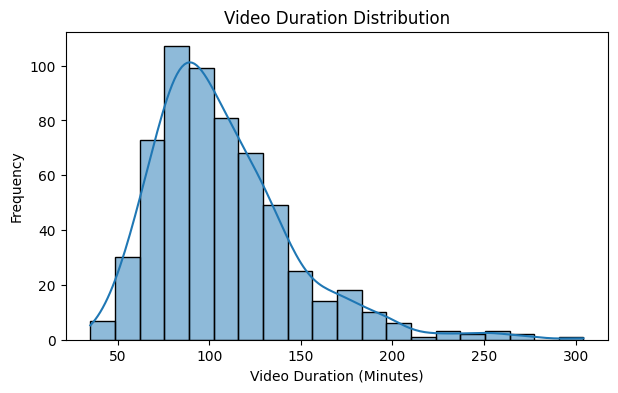

In [26]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="duration_minutes", bins=20, kde=True)

plt.title("Video Duration Distribution")
plt.xlabel("Video Duration (Minutes)")
plt.ylabel("Frequency")

plt.show()

### Quick insight
Most videos are long-form, but the durations still vary a lot. I keep the distribution visible rather than relying on the average alone.


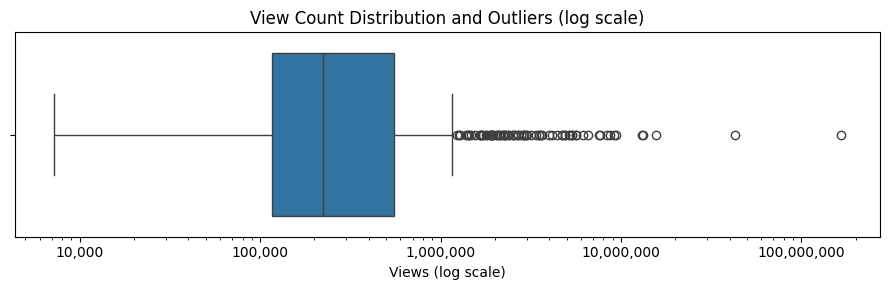

In [27]:
# Views are very skewed, so I use a log scale
fig, ax = plt.subplots(figsize=(9, 3))
sns.boxplot(x=df.loc[df["views"] > 0, "views"], ax=ax)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.set_title("View Count Distribution and Outliers (log scale)")
ax.set_xlabel("Views (log scale)")
plt.tight_layout()
plt.show()

### Quick insight
Views are strongly right-skewed. A small number of videos sit far above the rest, so the log scale makes the spread easier to read.


In [28]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

lower, upper

(-532891.5, 1200400.5)

In [29]:
outliers = df[
    (df["views"] < lower) |
    (df["views"] > upper)
]

print("Number of outliers:", len(outliers))
print(outliers[["views"]])

Number of outliers: 76
        views
0   165305543
1    43118967
..        ...
78    1266297
79    1237159

[76 rows x 1 columns]


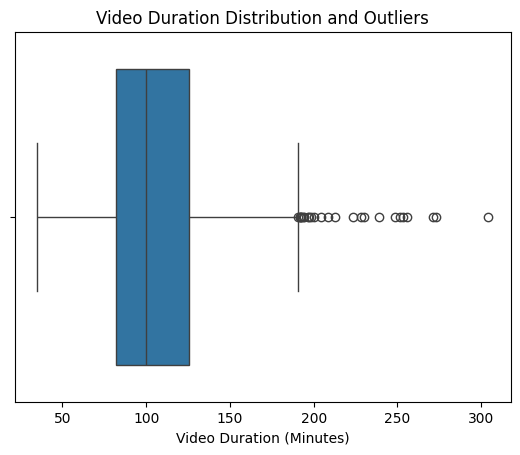

In [30]:
sns.boxplot(x=df['duration_minutes'])
plt.title("Video Duration Distribution and Outliers")
plt.xlabel("Video Duration (Minutes)")
plt.show()

### Quick insight
Most videos are long-form, but the durations still vary a lot. I keep the distribution visible rather than relying on the average alone.


In [31]:
Q1 = df["duration_minutes"].quantile(0.25)
Q3 = df["duration_minutes"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

lower, upper

(17.133333333333326, 190.8)

In [32]:
outliers = df[
    (df["duration_minutes"] < lower) |
    (df["duration_minutes"] > upper)
]

print("Number of outliers:", len(outliers))
print(outliers[["duration_minutes"]])

Number of outliers: 25
     duration_minutes
1          192.700000
3          223.616667
..                ...
505        196.633333
580        191.950000

[25 rows x 1 columns]


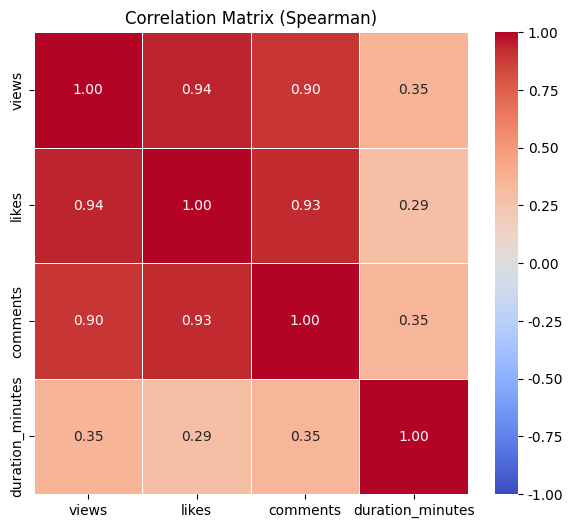

In [33]:
numeric_cols = ["views", "likes", "comments", "duration_minutes"]

# The numbers are skewed, so I use Spearman here
corr = df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5)

plt.title("Correlation Matrix (Spearman)")
plt.show()

### Quick insight
Views and likes move together strongly. The relationship between duration and views is positive but much weaker, so length alone does not explain performance.


Pearson correlation: 0.9770762002411545
Spearman correlation: 0.9380562836132056


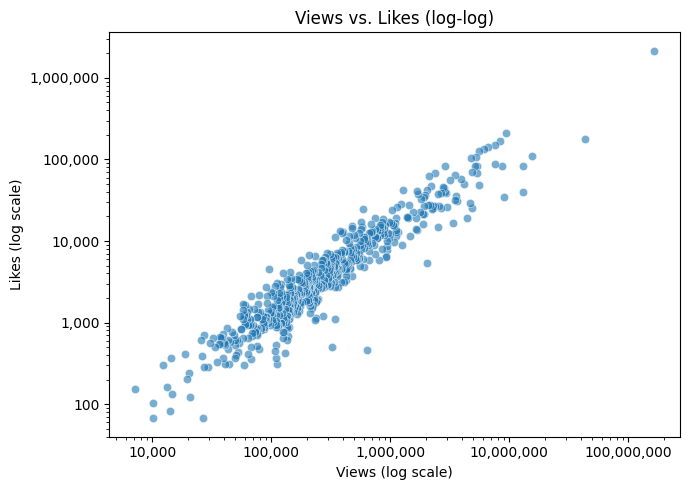

In [34]:
data = df[["views", "likes"]].dropna()

print("Pearson correlation:", data["views"].corr(data["likes"]))
print("Spearman correlation:", data["views"].corr(
    data["likes"], method="spearman"
))

pos = data[(data["views"] > 0) & (data["likes"] > 0)]

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=pos, x="views", y="likes", alpha=0.6, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Views vs. Likes (log-log)")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Likes (log scale)")
plt.tight_layout()
plt.show()

### Quick insight
Videos with more views usually have more likes too. This is a strong association, but it does not mean views cause likes.


Spearman correlation: 0.3515710617531512


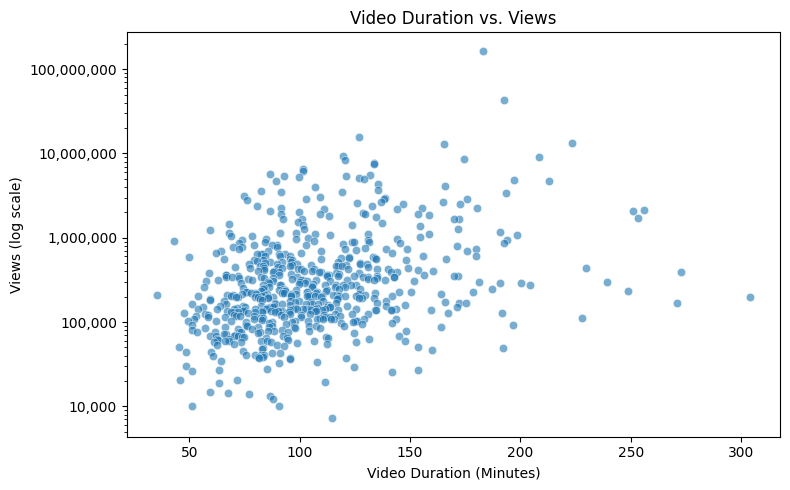

In [35]:
data = df[["duration_minutes", "views"]].dropna()

print("Spearman correlation:", data["duration_minutes"].corr(
    data["views"], method="spearman"
))

pos = data[data["views"] > 0]

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=pos, x="duration_minutes", y="views", alpha=0.6, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Video Duration vs. Views")
ax.set_xlabel("Video Duration (Minutes)")
ax.set_ylabel("Views (log scale)")
plt.tight_layout()
plt.show()

### Quick insight
There is a positive relationship between duration and views, but it is not especially strong. Longer videos may get more views on average, though other factors matter.


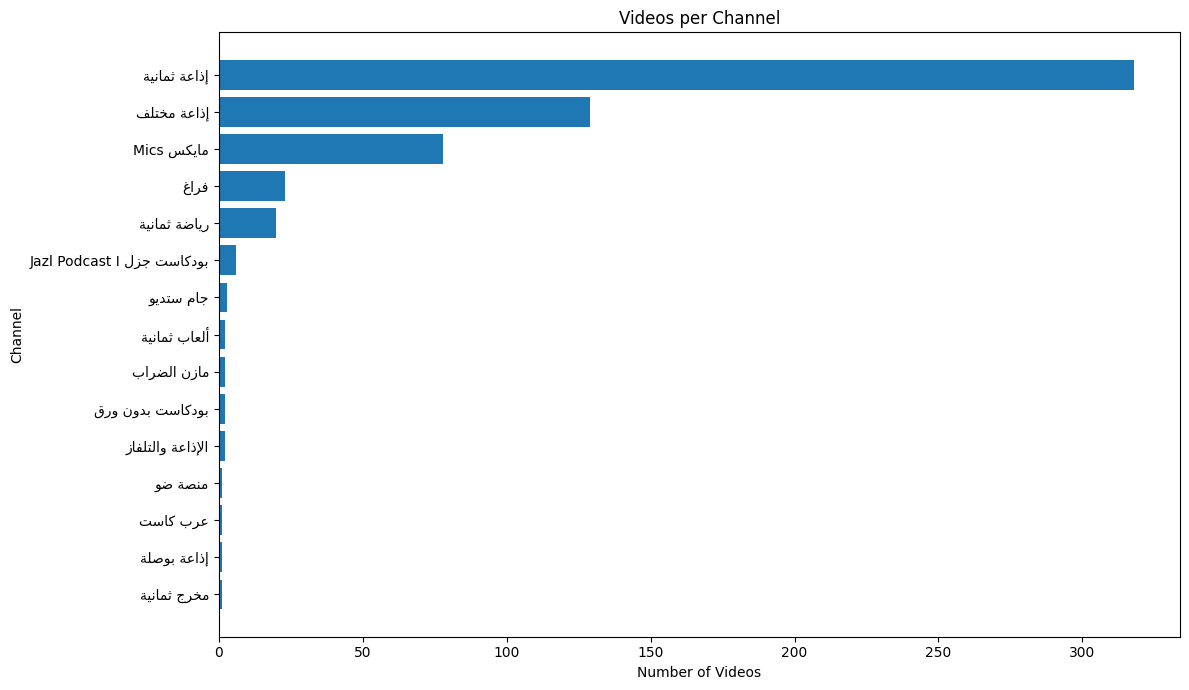

In [36]:
channel_counts = df["channel_name"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    [ar(name) for name in channel_counts.index],
    channel_counts.values
)

ax.set_title("Videos per Channel")
ax.set_xlabel("Number of Videos")
ax.set_ylabel("Channel")

ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Quick insight
The dataset is concentrated in a few channels. This means channel-level comparisons should be read with the number of videos in mind.


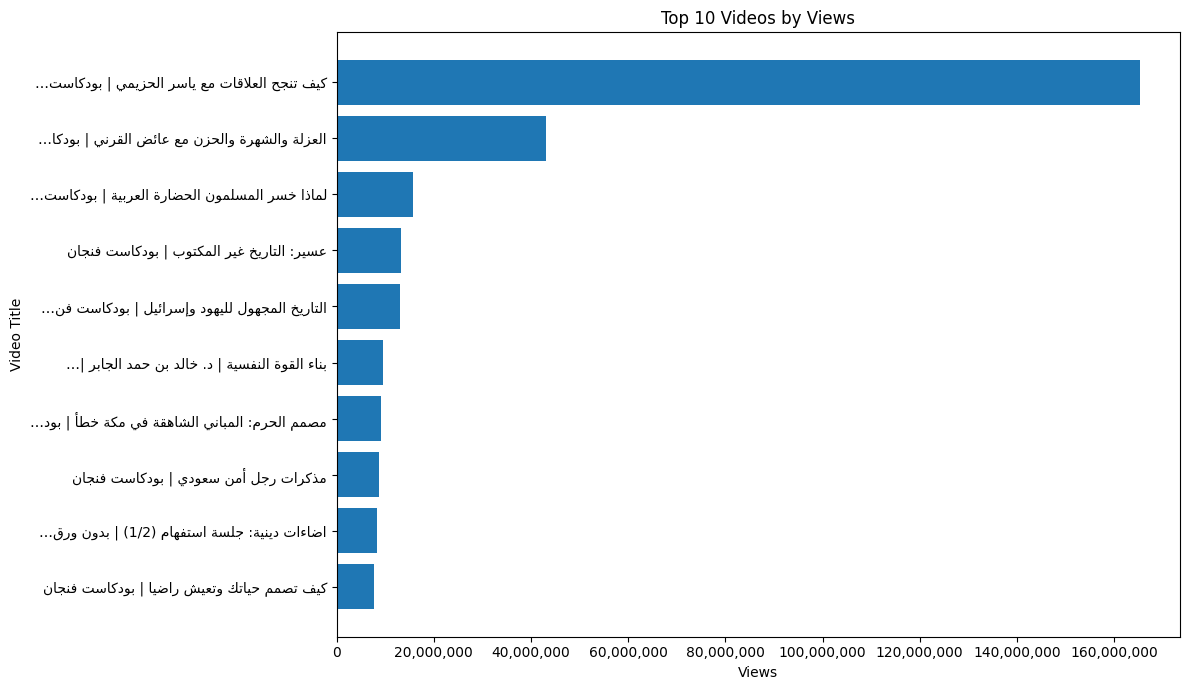

In [37]:
top_videos = df.nlargest(10, "views").copy()

fig, ax = plt.subplots(figsize=(12, 7))
barh_labeled(
    ax,
    [short_ar(t) for t in top_videos["video_title"]],
    top_videos["views"],
)
ax.xaxis.set_major_formatter(thousands)
ax.set_title("Top 10 Videos by Views")
ax.set_xlabel("Views")
ax.set_ylabel("Video Title")
plt.tight_layout()
plt.show()

### Quick insight
The top-viewed list is dominated by a few standout videos. I keep these videos in the analysis because they are real observations, but they can pull averages upward.


Correlation between comments and views: 0.8975671001229237
Correlation between comments and likes: 0.92581832853494
Videos drawn: 598 of 599


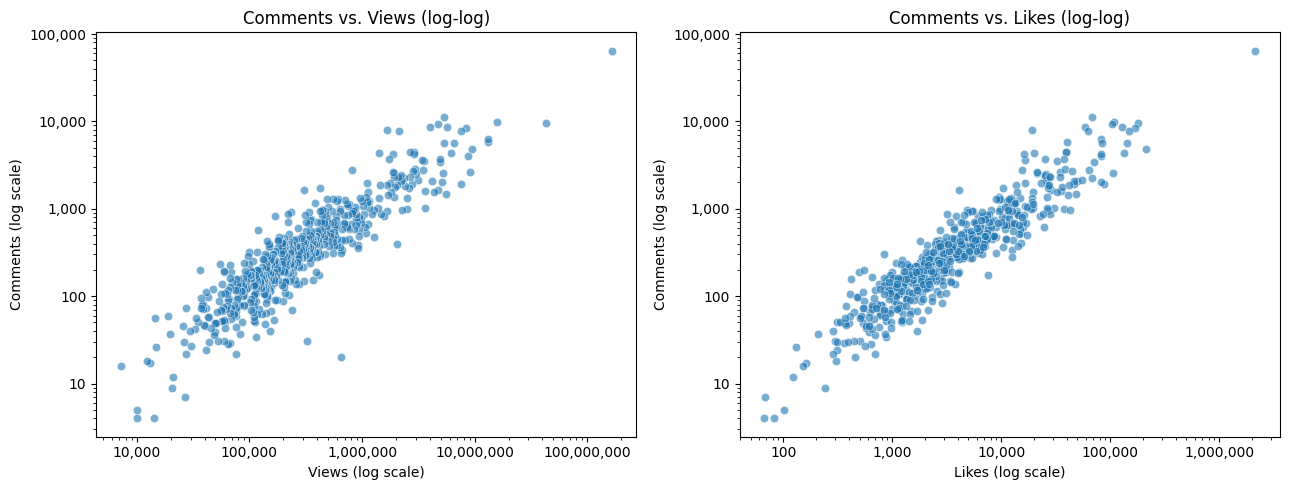

In [38]:
data = df[["views", "likes", "comments"]].dropna()

print("Correlation between comments and views:",
      data["comments"].corr(data["views"], method="spearman"))

print("Correlation between comments and likes:",
      data["comments"].corr(data["likes"], method="spearman"))

# Comments with a value of 0 cannot appear on a log scale, so I only plot
# comments > 0 are drawn (a log axis cannot show zeros anyway)
pos = data[(data[["views", "likes", "comments"]] > 0).all(axis=1)]
print("Videos drawn:", len(pos), "of", len(data))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=pos, x="views", y="comments", alpha=0.6, ax=axes[0])
axes[0].set_title("Comments vs. Views (log-log)")
axes[0].set_xlabel("Views (log scale)")
axes[0].set_ylabel("Comments (log scale)")

sns.scatterplot(data=pos, x="likes", y="comments", alpha=0.6, ax=axes[1])
axes[1].set_title("Comments vs. Likes (log-log)")
axes[1].set_xlabel("Likes (log scale)")
axes[1].set_ylabel("Comments (log scale)")

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.xaxis.set_major_formatter(thousands)
    ax.yaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()

### Quick insight
Comments are strongly related to both views and likes. The scatterplots only show videos with positive counts because zeros do not work on a log scale.


## More things I checked


In [39]:
df_extra = df.copy()

for col in ["views", "likes", "comments", "duration_minutes"]:
    if col in df_extra.columns:
        df_extra[col] = pd.to_numeric(df_extra[col], errors="coerce")

df_extra["published_at"] = pd.to_datetime(
    df_extra["published_at"], errors="coerce", utc=True
).dt.tz_convert("Asia/Riyadh")

sns.set_theme(style="whitegrid")
use_arabic_font()  # sns.set_theme() resets the font, so apply it again
plt.rcParams["figure.figsize"] = (12, 6)

print("Extra analysis copy ready:", df_extra.shape)

Extra analysis copy ready: (599, 18)


### 1. Like Rate per View



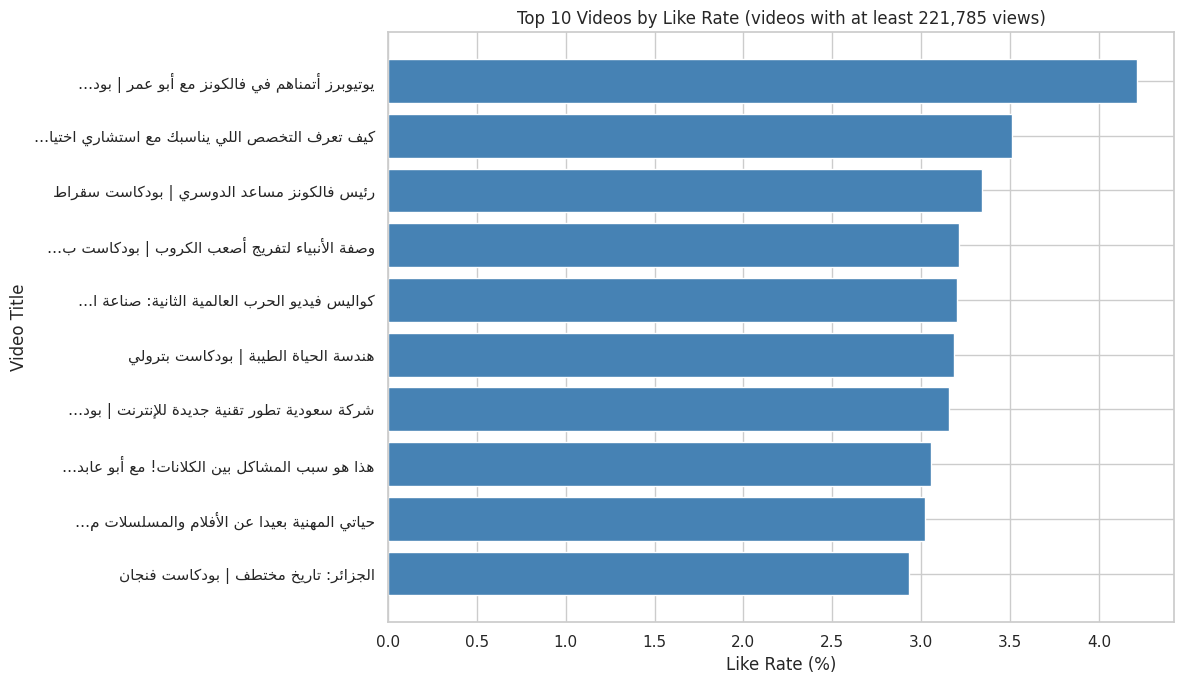

In [40]:
engagement_df = df_extra[
    df_extra["views"].gt(0) & df_extra["likes"].notna()
].copy()

engagement_df["like_rate"] = (
    engagement_df["likes"] / engagement_df["views"] * 100
)

# I use the median views as a cutoff so tiny videos do not dominate
# views, so only videoss at or above the median view count are ranked
min_views = engagement_df["views"].median()
eligible = engagement_df[engagement_df["views"] >= min_views]
top_engagement = eligible.nlargest(10, "like_rate")

fig, ax = plt.subplots(figsize=(12, 7))
barh_labeled(
    ax,
    [short_ar(t) for t in top_engagement["video_title"]],
    top_engagement["like_rate"],
    color="steelblue",
)
ax.set_title(
    f"Top 10 Videos by Like Rate (videos with at least {min_views:,.0f} views)"
)
ax.set_xlabel("Like Rate (%)")
ax.set_ylabel("Video Title")
plt.tight_layout()
plt.show()

### Quick insight
Like rate helps surface videos that get a lot of likes relative to their views. I apply a median-views cutoff so very small videos do not take over the ranking.


### 2. Views by Publication Day



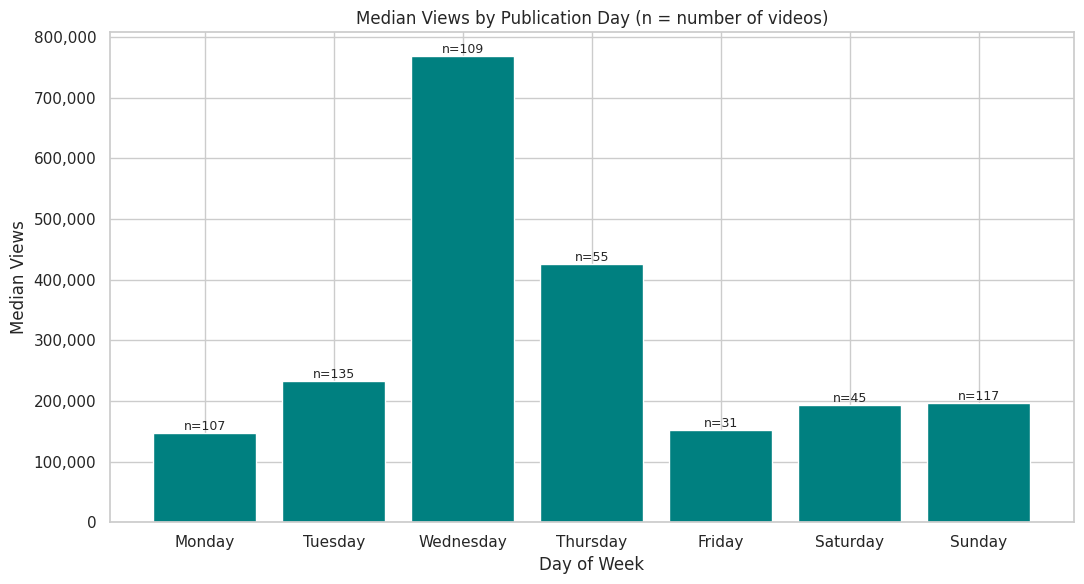

,day_name,mean,median,count
day_num,,,,
0,Monday,279049.336449,147927.0,107
1,Tuesday,449382.851852,232559.0,135
...,...,...,...,...
5,Saturday,300650.044444,193951.0,45
6,Sunday,289218.034188,196496.0,117


In [41]:
days_df = df_extra.dropna(subset=["published_at", "views"]).copy()
days_df["day_num"] = days_df["published_at"].dt.dayofweek
day_names = {
    0: "Monday", 1: "Tuesday", 2: "Wednesday", 3: "Thursday",
    4: "Friday", 5: "Saturday", 6: "Sunday"
}

day_stats = (
    days_df.groupby("day_num")["views"]
    .agg(["mean", "median", "count"])
    .reindex(range(7))
)
day_stats["count"] = day_stats["count"].fillna(0).astype(int)
day_stats["day_name"] = day_stats.index.map(day_names)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(day_stats["day_name"], day_stats["median"].fillna(0),
              color="teal")
for bar, n in zip(bars, day_stats["count"]):
    ax.annotate(f"n={n}", (bar.get_x() + bar.get_width() / 2,
                           bar.get_height()),
                ha="center", va="bottom", fontsize=9)

ax.yaxis.set_major_formatter(thousands)
ax.set_title("Median Views by Publication Day (n = number of videos)")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Median Views")
plt.tight_layout()
plt.show()

display(day_stats[["day_name", "mean", "median", "count"]])

### Quick insight
Median views by day are more useful than the mean here because viral videos can skew the average. The number of videos per day also matters when comparing days.


### 3. Total Channel Views vs. Median Views per Video

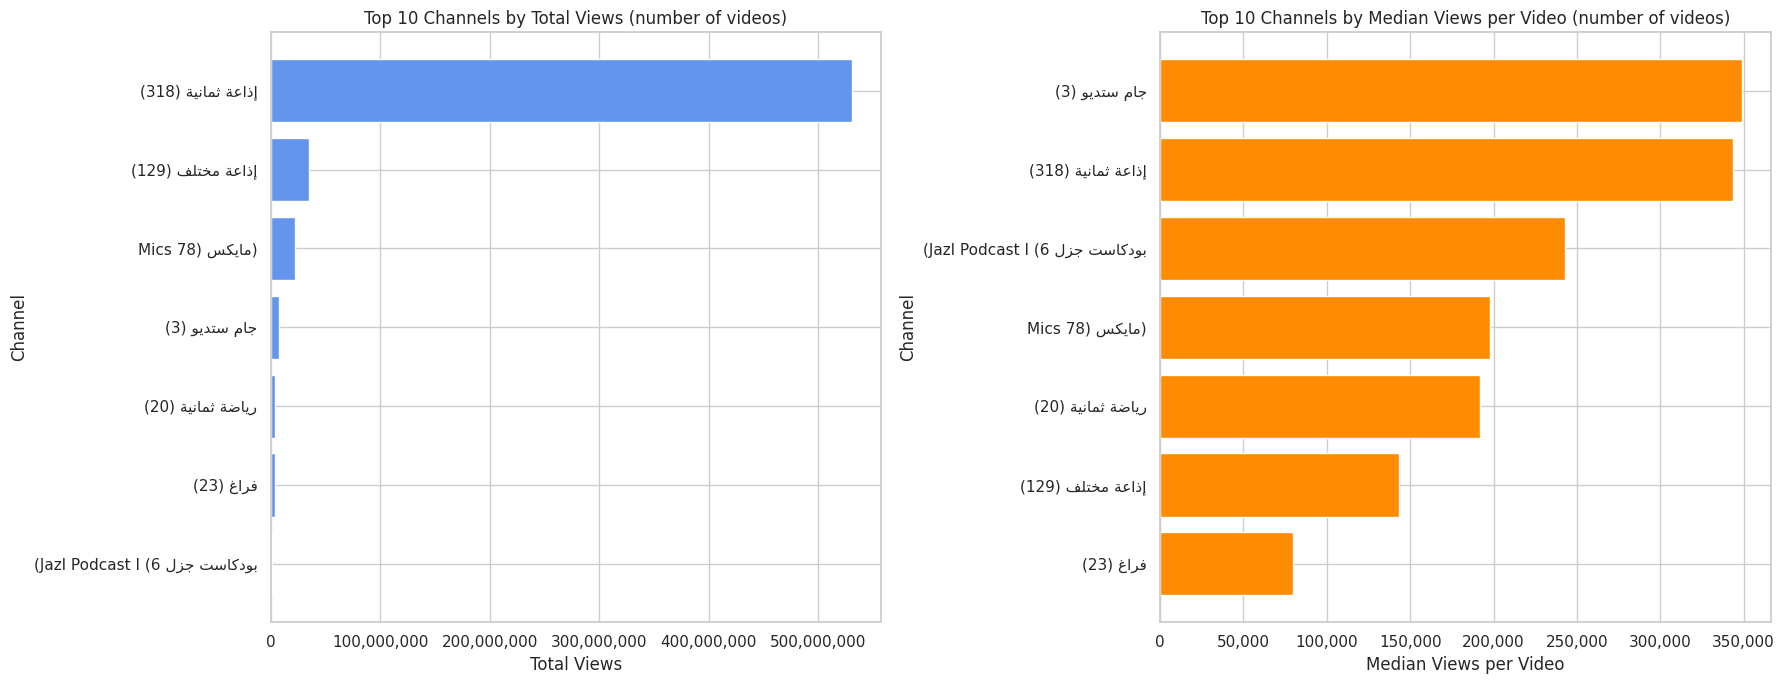

In [42]:
MIN_VIDEOS = 3  # I only compare channels with at least 3 videos

channel_df = df_extra.dropna(subset=["channel_name", "views"]).copy()
channel_stats = (
    channel_df.groupby("channel_name")
    .agg(
        total_views=("views", "sum"),
        median_views=("views", "median"),
        video_count=("video_id", "nunique")
    )
    .reset_index()
)
channel_stats = channel_stats[channel_stats["video_count"] >= MIN_VIDEOS].copy()

# Label = channel name + number of videos, e.g. "name (12)"
channel_stats["label"] = [
    ar(f"{name} ({n})")
    for name, n in zip(channel_stats["channel_name"],
                       channel_stats["video_count"])
]

top_channels_total = channel_stats.nlargest(10, "total_views")
top_channels_median = channel_stats.nlargest(10, "median_views")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

barh_labeled(axes[0], top_channels_total["label"],
             top_channels_total["total_views"], color="cornflowerblue")
axes[0].set_title("Top 10 Channels by Total Views (number of videos)")
axes[0].set_xlabel("Total Views")
axes[0].set_ylabel("Channel")

barh_labeled(axes[1], top_channels_median["label"],
             top_channels_median["median_views"], color="darkorange")
axes[1].set_title("Top 10 Channels by Median Views per Video (number of videos)")
axes[1].set_xlabel("Median Views per Video")
axes[1].set_ylabel("Channel")

for ax in axes:
    ax.xaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()

### Quick insight
Total views reward channels with more videos, while median views per video gives a better sense of a typical upload. I look at both instead of using only one ranking.


### 4. View Distribution and Outliers



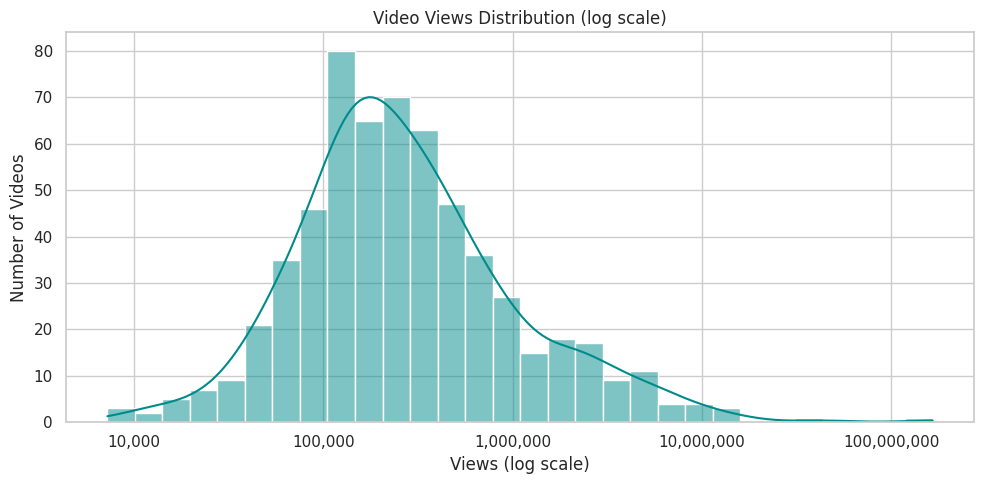

,Views statistics
count,5.990000e+02
mean,1.061157e+06
...,...
75%,5.504160e+05
max,1.653055e+08


In [43]:
views_values = df_extra.loc[
    df_extra["views"].notna() & df_extra["views"].gt(0), "views"
]

# A few viral videos stretch the scale,
# so I plot views on a log scale
log_views = np.log10(views_values)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(log_views, bins=30, kde=True, color="darkcyan", ax=ax)

ticks = np.arange(np.floor(log_views.min()), np.ceil(log_views.max()) + 1)
ticks = ticks[(ticks >= log_views.min()) & (ticks <= log_views.max())]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{10 ** t:,.0f}" for t in ticks])

ax.set_title("Video Views Distribution (log scale)")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Number of Videos")
plt.tight_layout()
plt.show()

display(views_values.describe().to_frame("Views statistics"))

### Quick insight
The log-scale distribution makes the long tail easier to see. Most videos are far below the very largest outliers.


### 5. View Counts across Channels

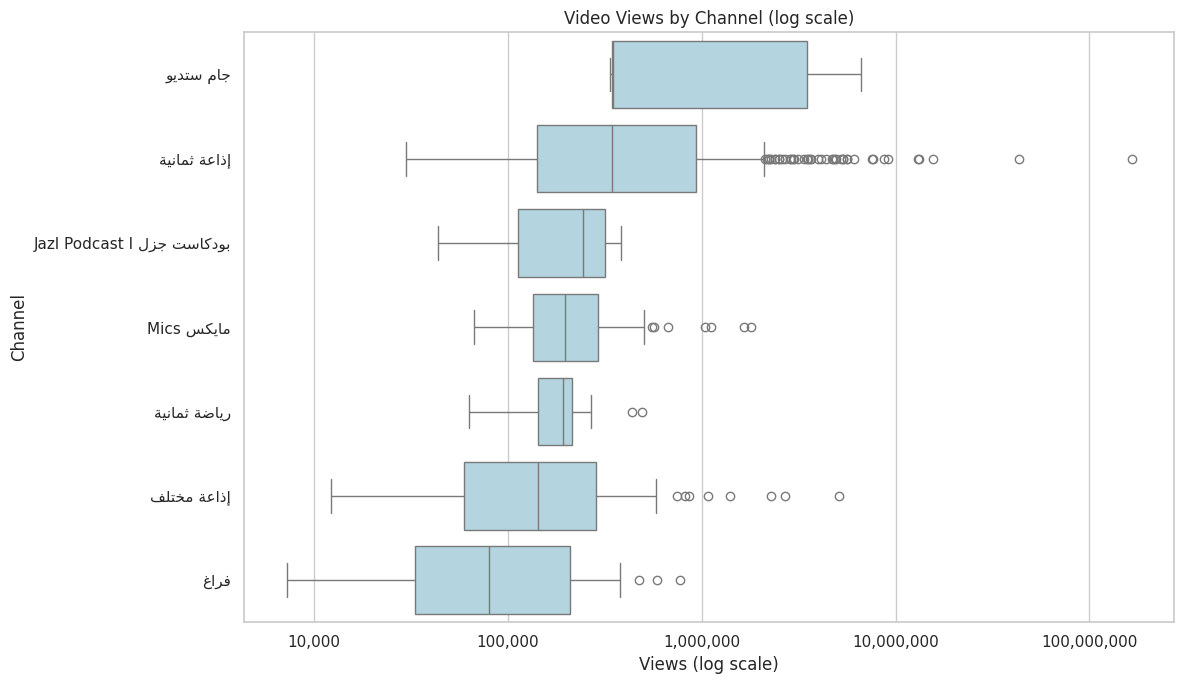

In [44]:
box_df = df_extra.dropna(subset=["channel_name", "views"]).copy()
channel_counts = box_df["channel_name"].value_counts()
eligible_channels = channel_counts[channel_counts >= 3].index
box_df = box_df[box_df["channel_name"].isin(eligible_channels)].copy()

selected_channels = box_df["channel_name"].value_counts().head(10).index
box_df = box_df[
    box_df["channel_name"].isin(selected_channels) & box_df["views"].gt(0)
].copy()

# Sort channels by median views and fix the Arabic labels
order = (
    box_df.groupby("channel_name")["views"].median()
    .sort_values(ascending=False).index
)
box_df["channel_ar"] = box_df["channel_name"].apply(ar)
order_ar = [ar(c) for c in order]

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=box_df, x="views", y="channel_ar", order=order_ar,
            orient="h", color="lightblue", ax=ax)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.set_title("Video Views by Channel (log scale)")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Channel")
plt.tight_layout()
plt.show()

### Quick insight
The channel boxplots show the spread within each channel, not just a single typical value. A channel can have a high median and still have a wide range of results.
